# RDKit 입문 + 데이터 탐색

이 노트북의 목적은 두 가지다.

1. **RDKit을 처음 쓰는 데 필요한 것만 익힌다** — SMILES 파싱, descriptor,
   fingerprint, scaffold. 이 네 가지로 1~2주차를 다 할 수 있다.
2. **세 과제의 데이터를 눈으로 본다** — 분자 몇 개인지, 타깃 분포가 어떤지,
   파싱 안 되는 SMILES가 있는지.

PK 쪽 비유를 하나 들면, descriptor는 물성값(logP, TPSA)이고 fingerprint는
구조를 비트로 적은 지문이다. 앞의 것은 해석이 쉽고 뒤의 것은 표현력이 크다.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd

from src import features
from src.config import TASKS

## 1. SMILES 파싱

RDKit의 모든 작업은 `Chem.MolFromSmiles`로 시작한다. 실패하면 `None`을
돌려주고 예외를 던지지 않으므로, 반드시 확인해야 한다.

원자 수   : 19
MolWt     : 259.35
MolLogP   : 2.58
TPSA      : 41.49


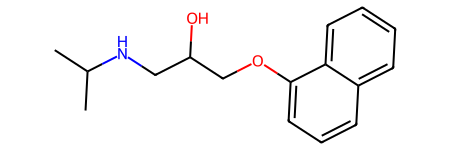

In [2]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors

# 프로프라놀롤 — 내 1저자 PBPK 논문의 그 약물
smiles = "CC(C)NCC(O)COc1cccc2ccccc12"
mol = Chem.MolFromSmiles(smiles)

print("원자 수   :", mol.GetNumAtoms())
print("MolWt     :", round(Descriptors.MolWt(mol), 2))
print("MolLogP   :", round(Descriptors.MolLogP(mol), 2))
print("TPSA      :", round(Descriptors.TPSA(mol), 2))

mol

In [3]:
# 깨진 SMILES는 None이 된다 — 이걸 처리하지 않으면 나중에 조용히 틀린다
print(Chem.MolFromSmiles("C1CC1C("))

None


## 2. Descriptor

`src/features.py`에 ADMET에서 널리 쓰는 27개를 골라 뒀다. 전체 200여 개를
다 쓰면 결측·무한값 처리가 번거롭고 과적합도 쉽다.

In [4]:
drugs = {
    "propranolol": "CC(C)NCC(O)COc1cccc2ccccc12",
    "omeprazole":  "CC1=CN=C(C(=C1OC)C)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC",
    "escitalopram":"CN(C)CCC[C@]1(c2ccc(F)cc2)OCc2cc(C#N)ccc21",
    "caffeine":    "Cn1cnc2c1c(=O)n(C)c(=O)n2C",
}

desc = features.descriptors(list(drugs.values()))
pd.DataFrame(desc, index=drugs.keys(), columns=features.DESCRIPTOR_NAMES).T.round(2)

,propranolol,omeprazole,escitalopram,caffeine
MolWt,259.35,345.42,324.40,194.19
MolLogP,2.58,2.90,3.81,-1.03
MolMR,78.59,93.02,90.91,51.20
TPSA,41.49,77.10,36.26,61.82
LabuteASA,113.76,142.24,141.83,79.03
NumHDonors,2.00,1.00,0.00,0.00
NumHAcceptors,3.00,5.00,3.00,6.00
NumRotatableBonds,6.00,5.00,5.00,0.00
NumHeteroatoms,3.00,7.00,4.00,6.00
HeavyAtomCount,19.00,24.00,24.00,14.00


## 3. Morgan fingerprint

반지름 2, 2048비트. 각 비트는 "이런 부분 구조가 있는가"를 뜻한다.
두 분자의 유사도는 겹치는 비트로 계산한다 (Tanimoto).

In [5]:
fp = features.morgan(list(drugs.values()))
print("모양:", fp.shape)
print("프로프라놀롤에서 켜진 비트 수:", int(fp[0].sum()))

# Tanimoto 유사도 — 구조가 비슷한 쌍을 확인한다
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in drugs.values()]
names = list(drugs)
sim = pd.DataFrame(
    [[round(DataStructs.TanimotoSimilarity(a, b), 3) for b in fps] for a in fps],
    index=names, columns=names,
)
sim

모양: (4, 2048)
프로프라놀롤에서 켜진 비트 수: 35


,propranolol,omeprazole,escitalopram,caffeine
propranolol,1.000,0.107,0.079,0.071
omeprazole,0.107,1.000,0.067,0.090
escitalopram,0.079,0.067,1.000,0.043
caffeine,0.071,0.090,0.043,1.000


## 4. Scaffold

분자의 골격만 남긴 것. TDC의 ADMET 분할이 scaffold를 기준으로 하므로,
**train과 test에 구조적으로 다른 분자가 들어간다.** 무작위 분할보다 어렵고,
실제 신약개발 상황(처음 보는 골격을 예측)에 가깝다.

In [6]:
from rdkit.Chem.Scaffolds import MurckoScaffold

for name, smi in drugs.items():
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(smiles=smi)
    print(f"{name:14} {scaffold}")

propranolol    c1ccc2ccccc2c1
omeprazole     O=S(Cc1ccccn1)c1nc2ccccc2[nH]1
escitalopram   c1ccc(C2OCc3ccccc32)cc1
caffeine       O=c1[nH]c(=O)c2[nH]cnc2[nH]1


## 5. TDC 데이터 불러오기

첫 실행에서 데이터를 내려받는다 (`../data/`에 캐시). 몇 분 걸릴 수 있다.

In [7]:
from src.data import get_group, load_task, xy

group = get_group()
split = load_task(group, "Caco2_Wang", seed=1)

for key in ("train", "valid", "test"):
    print(f"{key:6}: {len(split[key]):5d} 분자")

split["train"].head()

Found local copy...


generating training, validation splits...


  0%|          | 0/728 [00:00<?, ?it/s]

 41%|████      | 300/728 [00:00<00:00, 2974.60it/s]

 82%|████████▏ | 598/728 [00:00<00:00, 2950.22it/s]

100%|██████████| 728/728 [00:00<00:00, 2877.53it/s]

train :   637 분자
valid :    91 분자
test  :   182 분자


,Drug_ID,Drug,Y
0,PNU-184435,CC(=S)NC[C@H]1CN(c2ccc(N3CCCS(=O)CC3)c(F)c2)C(...,-5.338621
1,Valsartan,CCCCC(=O)N(Cc1ccc(-c2ccccc2-c2nnn[nH]2)cc1)[C@...,-6.260000
2,1,CCCN(Cc1ccoc1)C(=O)c1cc(C)cc(OCC2(CON=C(N)N)CC...,-5.387216
3,Telaprevir,CCC[C@H](NC(=O)[C@@H]1[C@H]2CCC[C@H]2CN1C(=O)[...,-5.390000
4,VX-950,CCC[C@H](NC(=O)C1[C@H]2CCC[C@H]2CN1C(=O)[C@@H]...,-5.320000


## 6. 세 과제 한눈에 보기

과제마다 분자 수, 타깃 단위, 분포가 다르다. PPBR은 퍼센트(0~100),
Caco-2는 로그 투과도, 마이크로솜 청소율은 오른쪽으로 길게 늘어진 분포다.
분포를 보고 로그 변환이 필요한지 판단한다.

In [8]:
rows = []
for task in TASKS:
    s = load_task(group, task, seed=1)
    all_smiles = (
        s["train"]["Drug"].tolist() + s["valid"]["Drug"].tolist() + s["test"]["Drug"].tolist()
    )
    y = pd.concat([s["train"]["Y"], s["valid"]["Y"], s["test"]["Y"]])
    rows.append({
        "task": task,
        "설명": TASKS[task]["label"],
        "지표": TASKS[task]["metric"],
        "분자 수": len(all_smiles),
        "파싱 실패": features.n_invalid(all_smiles),
        "Y 최소": round(y.min(), 3),
        "Y 중앙": round(y.median(), 3),
        "Y 최대": round(y.max(), 3),
    })

pd.DataFrame(rows).set_index("task")

generating training, validation splits...


  0%|          | 0/728 [00:00<?, ?it/s]

 41%|████▏     | 301/728 [00:00<00:00, 3007.26it/s]

 83%|████████▎ | 606/728 [00:00<00:00, 3031.44it/s]

100%|██████████| 728/728 [00:00<00:00, 2992.54it/s]

generating training, validation splits...


... (12 outputs left out)

 64%|██████▎   | 560/881 [00:00<00:00, 2808.43it/s]

 98%|█████████▊| 864/881 [00:00<00:00, 2905.43it/s]

100%|██████████| 881/881 [00:00<00:00, 2875.88it/s]

,설명,지표,분자 수,파싱 실패,Y 최소,Y 중앙,Y 최대
task,,,,,,,
Caco2_Wang,"Caco-2 투과도 (log Papp, cm/s)",mae,910,0,-7.76,-5.131,-3.51
PPBR_AZ,혈장단백결합률 (%),mae,2790,0,10.09,94.680,99.95
Clearance_Microsome_AZ,간 마이크로솜 고유 청소율 (uL/min/mg),spearman,1102,0,3.00,12.735,150.00


generating training, validation splits...


  0%|          | 0/728 [00:00<?, ?it/s]

 40%|████      | 294/728 [00:00<00:00, 2914.07it/s]

 81%|████████  | 591/728 [00:00<00:00, 2945.29it/s]

100%|██████████| 728/728 [00:00<00:00, 2877.15it/s]


generating training, validation splits...


... (10 outputs left out)

  0%|          | 0/881 [00:00<?, ?it/s]

 33%|███▎      | 292/881 [00:00<00:00, 2910.62it/s]

 66%|██████▋   | 584/881 [00:00<00:00, 2844.62it/s]

100%|██████████| 881/881 [00:00<00:00, 2902.90it/s]

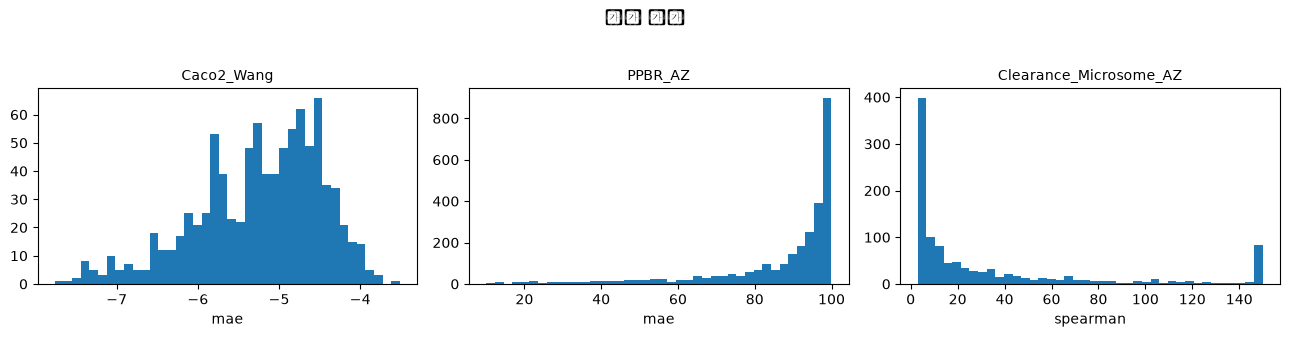

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(TASKS), figsize=(13, 3.2))
for ax, task in zip(axes, TASKS):
    s = load_task(group, task, seed=1)
    y = pd.concat([s["train"]["Y"], s["valid"]["Y"], s["test"]["Y"]])
    ax.hist(y, bins=40)
    ax.set_title(task, fontsize=10)
    ax.set_xlabel(TASKS[task]["metric"])
fig.suptitle("타깃 분포", y=1.04)
fig.tight_layout()

## 다음 단계

여기까지 되면 1주차 베이스라인을 돌릴 수 있다.

```bash
python scripts/run_baseline.py --tasks Caco2_Wang --models rf --features desc --seeds 1   # 빠른 확인
python scripts/run_baseline.py                                                            # 전체
```

결과는 `results/baseline.csv`에 저장된다. 2주차 PyTorch 모델은 이 숫자를
기준으로 평가한다.